# Crimes Analysis on US Populations
Project B.

Lets begin by adding and loading all the packages that will be useful along the notebook.

In [4]:
using Pkg
# Ensure required packages (uncomment to install if needed)
Pkg.add([
    "MLJ", 
    "MLJBase", 
    "MLJModels", 
    "MLJEnsembles", 
    "MLJLinearModels", 
    "DecisionTree", 
    "MLJDecisionTreeInterface",
    "NaiveBayes",
    "MLJNaiveBayesInterface", 
    "EvoTrees", 
    "CategoricalArrays", 
    "Random",
    "LIBSVM",           
    "MLJLIBSVMInterface", 
    "Plots",
    "MLJModelInterface",
    "CSV",       
    "DataFrames",      
    "UrlDownload",
    "XGBoost",
    "MultivariateStats",
    "MLJMultivariateStatsInterface",
    "TSne"
])

   Resolving package versions...
  No Changes to `~/.julia/environments/v1.9/Project.toml`
  No Changes to `~/.julia/environments/v1.9/Manifest.toml`


In [6]:
using MLJ;
using Plots;
using TSne;
using DataFrames;
using CSV;
using CategoricalArrays;
using Random;
using Pkg;
PCA = MLJ.@load PCA pkg=MultivariateStats
ICA = MLJ.@load ICA pkg=MultivariateStats
LDA = MLJ.@load LDA pkg=MultivariateStats verbosity=0
ICA = MLJ.@load ICA pkg=MultivariateStats
# TSNE = MLJ.@load TSNE pkg=TSne

LogisticClassifier = @load LogisticClassifier pkg=MLJLinearModels verbosity=0
GaussianNBClassifier = @load GaussianNBClassifier pkg=NaiveBayes verbosity=0


import MLJMultivariateStatsInterface ✔
import MLJMultivariateStatsInterface ✔
import MLJMultivariateStatsInterface ✔


[ Info: For silent loading, specify `verbosity=0`. 
[ Info: For silent loading, specify `verbosity=0`. 
[ Info: For silent loading, specify `verbosity=0`. 


MLJNaiveBayesInterface.GaussianNBClassifier

In [226]:
# Finally lets import the functions created during the previous assignments
include("work/src/Preprocessing.jl")
include("work/src/Sampling.jl")
include("work/src/Training.jl")
include("work/src/Output.jl")


import MLJLIBSVMInterface ✔


[ Info: For silent loading, specify `verbosity=0`. 


Main.Output

## Loading data

The next phase is to load the data of our dataset and clean it. The dataset cames as two files the first one is a CSV with all the data (`communities.data`) and the second one (`communities.names`) gives information about the preprocessing being done.

The data cames with missing values which are marked as '?', these values where transformed into missing values to help the dataframe detect the type of each column.

Notice that we won't normalize the data as it has been previously normalize between 0 and 1 retaining their distribution and skew.

In [227]:
Random.seed!(1234); # For reproducibility

# Laoding data
df = CSV.read("data/communities.data", DataFrame; header=false, missingstring="?");
df

Row,Column1,Column2,Column3,Column4,Column5,Column6,Column7,Column8,Column9,Column10,Column11,Column12,Column13,Column14,Column15,Column16,Column17,Column18,Column19,Column20,Column21,Column22,Column23,Column24,Column25,Column26,Column27,Column28,Column29,Column30,Column31,Column32,Column33,Column34,Column35,Column36,Column37,Column38,Column39,Column40,Column41,Column42,Column43,Column44,Column45,Column46,Column47,Column48,Column49,Column50,Column51,Column52,Column53,Column54,Column55,Column56,Column57,Column58,Column59,Column60,Column61,Column62,Column63,Column64,Column65,Column66,Column67,Column68,Column69,Column70,Column71,Column72,Column73,Column74,Column75,Column76,Column77,Column78,Column79,Column80,Column81,Column82,Column83,Column84,Column85,Column86,Column87,Column88,Column89,Column90,Column91,Column92,Column93,Column94,Column95,Column96,Column97,Column98,Column99,Column100,⋯
,Int64,Int64?,Int64?,String31,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,8,missing,missing,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,⋯
2,53,missing,missing,Tukwilacity,1,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,⋯
3,24,missing,missing,Aberdeentown,1,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,⋯
4,34,5,81440,Willingborotownship,1,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,0.21,0.19,0.75,0.7,0.77,0.89,0.63,0.51,0.47,0.0,0.0,0.19,0.3,0.73,0.64,⋯
5,42,95,6096,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,0.02,0.9,0.5,0.72,0.16,0.68,0.44,0.11,0.71,0.46,0.43,0.41,0.28,0.0,0.74,0.51,0.48,0.0,0.06,0.25,0.3,0.33,0.12,0.65,0.67,0.38,0.42,0.46,0.22,0.27,0.2,0.21,0.51,0.91,0.91,0.89,0.85,0.4,0.6,0.0,0.06,0.0,0.03,0.07,0.2,0.27,0.01,0.02,

After importing the data we change the name of the columns by its corresponding one and then we make a first quick analysis.

In [228]:
#TODO: Add column names to CSV
header_string = "state, county, community, communityname, fold, population, householdsize, racepctblack, racePctWhite, racePctAsian, racePctHisp, agePct12t21, agePct12t29, agePct16t24, agePct65up, numbUrban, pctUrban, medIncome, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, medFamInc, perCapInc, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, NumUnderPov, PctPopUnderPov, PctLess9thGrade, PctNotHSGrad, PctBSorMore, PctUnemployed, PctEmploy, PctEmplManu, PctEmplProfServ, PctOccupManu, PctOccupMgmtProf, MalePctDivorce, MalePctNevMarr, FemalePctDiv, TotalPctDiv, PersPerFam, PctFam2Par, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMomYoungKids, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec5, PctImmigRec8, PctImmigRec10, PctRecentImmig, PctRecImmig5, PctRecImmig8, PctRecImmig10, PctSpeakEnglOnly, PctNotSpeakEnglWell, PctLargHouseFam, PctLargHouseOccup, PersPerOccupHous, PersPerOwnOccHous, PersPerRentOccHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctHousOwnOcc, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, OwnOccMedVal, OwnOccHiQuart, RentLowQ, RentMedian, RentHighQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctBornSameState, PctSameHouse85, PctSameCity85, PctSameState85, LemasSwornFT, LemasSwFTPerPop, LemasSwFTFieldOps, LemasSwFTFieldPerPop, LemasTotalReq, LemasTotReqPerPop, PolicReqPerOffic, PolicPerPop, RacialMatchCommPol, PctPolicWhite, PctPolicBlack, PctPolicHisp, PctPolicAsian, PctPolicMinor, OfficAssgnDrugUnits, NumKindsDrugsSeiz, PolicAveOTWorked, LandArea, PopDens, PctUsePubTrans, PolicCars, PolicOperBudg, LemasPctPolicOnPatr, LemasGangUnitDeploy, LemasPctOfficDrugUn, PolicBudgPerPop, ViolentCrimesPerPop"
new_headers = [Symbol(strip(name)) for name in split(header_string, ',')]
rename!(df, Dict(names(df) .=> new_headers))
describe(df)

Row,variable,mean,min,median,max,nmissing,eltype
,Symbol,Union…,Any,Union…,Any,Int64,Type
1,state,28.6836,1,34.0,56,0,Int64
2,county,58.8268,1,23.0,840,1174,"Union{Missing, Int64}"
3,community,46188.3,70,48090.0,94597,1177,"Union{Missing, Int64}"
4,communityname,,Aberdeencity,,Zanesvillecity,0,String31
5,fold,5.49398,1,5.0,10,0,Int64
6,population,0.0575928,0.0,0.02,1.0,0,Float64
7,householdsize,0.463395,0.0,0.44,1.0,0,Float64
8,racepctblack,0.179629,0.0,0.06,1.0,0,Float64
9,racePctWhite,0.753716,0.0,0.85,1.0,0,Float64


## Cleaning data

The next phase of our analysis is cleaning the data to delete unnecessary variables and those which add more noise that information. If possible we will try not to delete variables but instead try to infer missing values.

In the previous cell a first analysis was done, where we detected a number of columns with the same number of missing values as rows in the dataset. We decided we will begin this section identifying them, to analysis the reason of those missing values.

In [229]:
# We detected a group of columns with the same number of missing values as rows in the dataset
n = 1675

# 2. Count the missing values for each column
missing_counts = map(col -> sum(ismissing, col), eachcol(df))
# Result: [1, 3, 0, 5, 1]

# 3. Find the indices where the count equals n
column_indices = findall(==(n), missing_counts)
# Result: [2] (Index for column B)

# 4. Get the column names using the indices
columns_with_n_missings = names(df)[column_indices]

22-element Vector{String}:
 "LemasSwornFT"
 "LemasSwFTPerPop"
 "LemasSwFTFieldOps"
 "LemasSwFTFieldPerPop"
 "LemasTotalReq"
 "LemasTotReqPerPop"
 "PolicReqPerOffic"
 "PolicPerPop"
 "RacialMatchCommPol"
 "PctPolicWhite"
 "PctPolicBlack"
 "PctPolicHisp"
 "PctPolicAsian"
 "PctPolicMinor"
 "OfficAssgnDrugUnits"
 "NumKindsDrugsSeiz"
 "PolicAveOTWorked"
 "PolicCars"
 "PolicOperBudg"
 "LemasPctPolicOnPatr"
 "LemasGangUnitDeploy"
 "PolicBudgPerPop"

We decided to remove these columns as they have to many missing values to infer them ($\approx 0.84\%$) and they are caused based on `communities.data` due to missing Law Enforcement Management and Administrative Statistics data on some communities.

In [230]:
# Remove all columns with n missing values
select!(df, Not(columns_with_n_missings))

Row,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,⋯
,Int64,Int64?,Int64?,String31,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,8,missing,missing,Lakewoodcity,1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,⋯
2,53,missing,missing,Tukwilacity,1,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,⋯
3,24,missing,missing,Aberdeentown,1,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,⋯
4,34,5,81440,Willingborotownship,1,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.9

The next thing to do is identify the rest of the variables with missing values so we can manage this missing values.

In [231]:
# See pending nulls columns
function describe_missing(df::DataFrame)
    
    pending_nulls = map(col -> sum(ismissing, col), eachcol(df))
    pending_nulls_dict = Dict(names(df) .=> pending_nulls)

    println("Columns with pending missing values:")
    for (col_name, miss_count) in pending_nulls_dict
        if miss_count > 0
            println("$col_name: $miss_count missing values")
        end
    end
end
describe_missing(df)

Columns with pending missing values:
community: 1177 missing values
OtherPerCap: 1 missing values
county: 1174 missing values


We identify the variable OtherPerCap which represents per capita income for people with heritage not coming from caucasians, african americans, native americans, asian, hispanic. As this is a numeric continuous variable, with only one missing values, we decided to infer the missing value instead of deleting the row.

To infer the missing value a mean was calculated and the value was replaced by this mean.

In [232]:
# Complete OtherPerCap missing values with the mean of the column
mean_otherpercap = mean(skipmissing(df.OtherPerCap))
df.OtherPerCap .= coalesce.(df.OtherPerCap, mean_otherpercap)
describe_missing(df)

Columns with pending missing values:
community: 1177 missing values
county: 1174 missing values


The next step was deleting other data identified as non predictive variables, which means that they are not useful to train our model to predict the goal variable.

In [233]:
# Removing not predictive Variables
select!(df, Not([:state, :county, :community, :communityname, :fold]))

Row,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,NumIlleg,PctIlleg,NumImmig,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,MedNumBR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,NumInShelters,NumStreet,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,LemasPctOfficDrugUn,⋯
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,⋯
1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.04,0.14,0.03,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.5,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.04,0.0,0.12,0.42,0.5,0.51,0.64,0.12,0.26,0.2,0.32,⋯
2,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.0,0.24,0.01,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.0,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.0,0.0,0.21,0.5,0.34,0.6,0.52,0.02,0.12,0.45,0.0,⋯
3,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.01,0.46,0.0,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.5,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.0,0.0,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.0,⋯
4,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.03,0.33,0.02,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.5,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,0

We continue by trying to find variables with all the values with the same value

In [234]:
# Access LemasPctOfficDrugUn
# Show statistics for LemasPctOfficDrugUn I want mean, median, mode, std
# TODO Probably delete this column
lemas_col = df.LemasPctOfficDrugUn
mean_lemas = mean(skipmissing(lemas_col))
median_lemas = median(skipmissing(lemas_col))
mode_lemas = mode(skipmissing(lemas_col))
std_lemas = std(skipmissing(lemas_col))
println("Statistics for LemasPctOfficDrugUn:")
println("Mean: $mean_lemas")
println("Median: $median_lemas")
println("Mode: $mode_lemas")
println("Standard Deviation: $std_lemas")

Statistics for LemasPctOfficDrugUn:
Mean: 0.09405215646940823
Median: 0.0
Mode: 0.0
Standard Deviation: 0.24032827792826494


In [235]:
"""
    detect_values_near_0(df::DataFrame, threshold::Float64, count::Int=0)

Identifies columns in a DataFrame where the number of values whose absolute 
magnitude is less than or equal to a given 'threshold' meets a specified 'count'.

# Arguments
- `df::DataFrame`: The input DataFrame.
- `threshold::Float64`: The maximum absolute value for a number to be considered "near 0".
- `count::Int=0`: The required number of "near 0" values for a column to be selected.

# Returns
- `near_0_cols::Vector{Symbol}`: A list of column names (Symbols) that meet the criteria.
"""
function detect_values_near_0(df::DataFrame, threshold::Float64, count::Int=0, verbose::Bool=true)::Vector{Symbol}
    
    # 1. Initialize variables and prepare for reporting
    near_0_cols = Symbol[]
    report = "Value Detection Report (Threshold: $threshold, Required Count: $count)\n"
    
    # 2. Iterate through each column in the DataFrame
    for col_name in names(df)
        col = df[!, col_name]
        
        # Check if the column elements are of a numeric type (Int, Float, etc.)
        if eltype(col) <: Number
            
            # Count how many values are near zero
            near_0_value_count = sum(abs.(col) .<= threshold)
            
            # Add to the report
            report *= "* Column `:$col_name`: Found $near_0_value_count values near 0.\n"
            
            # Check the criteria
            if near_0_value_count >= count
                push!(near_0_cols, Symbol(col_name))
            end
        else
            # Skip non-numeric columns and note it in the report
            report *= "* Column `:$col_name`: Skipped (Non-numeric Type: $(eltype(col))).\n"
        end
    end
    if verbose
        # 3. Print the full report
        println(report)
    end
    
    # 4. Final summary for the return value
    if isempty(near_0_cols)
        println("Result: No numeric columns matched the criteria (count == $count).")
    else
        println("Result: The following columns matched the criteria: $near_0_cols")
    end

    # 5. Return the list of matching column symbols
    return near_0_cols
end


detect_values_near_0

In [236]:
len_df = size(df)[1]
n= 0.3* len_df
# Cast n to Int
n = round(Int, n)
near_0_columns = detect_values_near_0(df, 0.00001, n, true)

println("Columns detected with near 0 values $(length(near_0_columns)):")
for col in near_0_columns
    println("Column to consider for removal due to near 0 values: $col")
end

Value Detection Report (Threshold: 1.0e-5, Required Count: 598)
* Column `:population`: Found 385 values near 0.
* Column `:householdsize`: Found 2 values near 0.
* Column `:racepctblack`: Found 134 values near 0.
* Column `:racePctWhite`: Found 33 values near 0.
* Column `:racePctAsian`: Found 8 values near 0.
* Column `:racePctHisp`: Found 59 values near 0.
* Column `:agePct12t21`: Found 2 values near 0.
* Column `:agePct12t29`: Found 1 values near 0.
* Column `:agePct16t24`: Found 1 values near 0.
* Column `:agePct65up`: Found 3 values near 0.
* Column `:numbUrban`: Found 568 values near 0.
* Column `:pctUrban`: Found 558 values near 0.
* Column `:medIncome`: Found 1 values near 0.
* Column `:pctWWage`: Found 15 values near 0.
* Column `:pctWFarmSelf`: Found 18 values near 0.
* Column `:pctWInvInc`: Found 1 values near 0.
* Column `:pctWSocSec`: Found 2 values near 0.
* Column `:pctWPubAsst`: Found 1 values near 0.
* Column `:pctWRetire`: Found 1 values near 0.
* Column `:medFamInc`

Tendremos esto en cuenta en futuros análisis, viendo el impacto de estas variables o su ausencia.

In [237]:
df_without_near0 = select(df, Not(near_0_columns))

Row,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,OtherPerCap,HispPerCap,NumUnderPov,PctPopUnderPov,PctLess9thGrade,PctNotHSGrad,PctBSorMore,PctUnemployed,PctEmploy,PctEmplManu,PctEmplProfServ,PctOccupManu,PctOccupMgmtProf,MalePctDivorce,MalePctNevMarr,FemalePctDiv,TotalPctDiv,PersPerFam,PctFam2Par,PctKids2Par,PctYoungKids2Par,PctTeen2Par,PctWorkMomYoungKids,PctWorkMom,PctIlleg,PctImmigRecent,PctImmigRec5,PctImmigRec8,PctImmigRec10,PctRecentImmig,PctRecImmig5,PctRecImmig8,PctRecImmig10,PctSpeakEnglOnly,PctNotSpeakEnglWell,PctLargHouseFam,PctLargHouseOccup,PersPerOccupHous,PersPerOwnOccHous,PersPerRentOccHous,PctPersOwnOccup,PctPersDenseHous,PctHousLess3BR,HousVacant,PctHousOccup,PctHousOwnOcc,PctVacantBoarded,PctVacMore6Mos,MedYrHousBuilt,PctHousNoPhone,PctWOFullPlumb,OwnOccLowQuart,OwnOccMedVal,OwnOccHiQuart,RentLowQ,RentMedian,RentHighQ,MedRent,MedRentPctHousInc,MedOwnCostPctInc,MedOwnCostPctIncNoMtg,PctForeignBorn,PctBornSameState,PctSameHouse85,PctSameCity85,PctSameState85,LandArea,PopDens,PctUsePubTrans,ViolentCrimesPerPop
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.19,0.33,0.02,0.9,0.12,0.17,0.34,0.47,0.29,0.32,0.2,1.0,0.37,0.72,0.34,0.6,0.29,0.15,0.43,0.39,0.4,0.39,0.32,0.27,0.27,0.36,0.41,0.08,0.19,0.1,0.18,0.48,0.27,0.68,0.23,0.41,0.25,0.52,0.68,0.4,0.75,0.75,0.35,0.55,0.59,0.61,0.56,0.74,0.76,0.14,0.24,0.27,0.37,0.39,0.07,0.07,0.08,0.08,0.89,0.06,0.14,0.13,0.33,0.39,0.28,0.55,0.09,0.51,0.21,0.71,0.52,0.05,0.26,0.65,0.14,0.06,0.22,0.19,0.18,0.36,0.35,0.38,0.34,0.38,0.46,0.25,0.12,0.42,0.5,0.51,0.64,0.12,0.26,0.2,0.2
2,0.0,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.3,0.22,0.35,0.01,0.24,0.14,0.24,0.3,0.27,0.73,0.57,0.15,0.42,0.36,1.0,0.63,0.91,1.0,0.29,0.43,0.47,0.6,0.39,0.46,0.53,0.24,0.52,0.62,0.64,0.63,0.25,0.27,0.25,0.23,0.84,0.1,0.16,0.1,0.17,0.29,0.17,0.26,0.2,0.82,0.02,0.79,0.24,0.02,0.25,0.65,0.16,0.0,0.21,0.2,0.21,0.42,0.38,0.4,0.37,0.29,0.32,0.18,0.21,0.5,0.34,0.6,0.52,0.02,0.12,0.45,0.67
3,0.0,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.0,0.0,0.3,0.58,0.19,0.39,0.38,0.4,0.84,0.28,0.27,0.29,0.27,0.07,0.29,0.28,0.39,0.01,0.27,0.27,0.43,0.19,0.36,0.58,0.32,0.29,0.49,0.32,0.63,0.41,0.71,0.7,0.45,0.42,0.44,0.43,0.43,0.71,0.67,0.46,0.07,0.06,0.15,0.19,0.02,0.02,0.04,0.05,0.88,0.04,0.2,0.2,0.46,0.52,0.43,0.42,0.15,0.51,0.01,0.86,0.41,0.29,0.3,0.52,0.47,0.45,0.18,0.17,0.16,0.27,0.29,0.27,0.31,0.48,0.39,0.28,0.14,0.49,0.54,0.67,0.56,0.01,0.21,0.02,0.43
4,0.04,0.77,1.0,0.08,0.12,0.1,0.51,0.5,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.2,0.82,0.51,0.36,0.4,0.39,0.16,0.25,0.36,0.44,0.01,0.1,0.09,0.25,0.31,0.33,0.71,0.36,0.45,0.37,0.39,0.34,0.45,0.49,0.44,0.75,0.65,0.54,0.83,0.65,0.85,0.86,0.33,0.11,0.2,0.3,0.31,0.05,0.08,0.11,0.11,0.81,0.08,0.56,0.62,0.85,0.77,1.0,0.94,0.12,0.01,0.01,0.97,0.96,0.6,0.47,0.52,0.11,0.11,0.24,0.21,0.19,0.75,0.7,0.77,0.89,0.63,0.51,0.47,0.19,0.3,0.73,0.64,0.65,0.02,0.39,0.28,0.12
5,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,0.02,0.9,0.5,0.72,0.16,0.68,0.44,0.11,0.

Our next step is to detect unvariant variables, those without variation in the whole dataset on their values. If found they will be deleted as they won't give any information for the regression but they will add noise.

In [238]:

"""
    detect_unvariant_variables(df::DataFrame)

Identifies columns in a DataFrame where all rows have the same value (i.e., the column is unvariant).

# Arguments
- `df::DataFrame`: The input DataFrame.

# Returns
- `unvariant_cols::Vector{Symbol}`: A list of column names (Symbols) that are unvariant.
"""
function detect_unvariant_variables(df::DataFrame; verbose::Bool=true)::Vector{Symbol}
    
    # 1. Initialize variables and prepare for reporting
    unvariant_cols = Symbol[]
    report = "Unvariant Variable Detection Report\n"
    
    # 2. Iterate through each column in the DataFrame
    for col_name in names(df)
        col = df[!, col_name]
        
        # Get the number of unique values in the column
        n_unique = length(unique(col))
        
        # Add to the report
        report *= "* Column `:$col_name`: Found $n_unique unique value(s). (Type: $(eltype(col)))\n"
        
        # Check the criteria: A column is unvariant if it has only 1 unique value
        if n_unique == 1
            push!(unvariant_cols, Symbol(col_name))
        end
    end
    
    if verbose
        # 3. Print the full report
        println(report)
    end
    # 4. Final summary for the return value
    if isempty(unvariant_cols)
        println("Result: No columns were found to be unvariant.")
    else
        println("Result: The following columns were found to be unvariant: $unvariant_cols")
    end

    # 5. Return the list of matching column symbols
    return unvariant_cols
end
detect_unvariant_variables(df; verbose=false)

Result: No columns were found to be unvariant.


Symbol[]

Finally we will make a fasta analysis in search of somethig wierd.

In [239]:
function fast_analysis(df::DataFrame, columns::Vector{Symbol})
    println("Fast Analysis Report:")
    for col_name in columns
        col = df[!, col_name]
        mean_val = mean(skipmissing(col))
        median_val = median(skipmissing(col))
        std_val = std(skipmissing(col))
        min = minimum(skipmissing(col))
        max = maximum(skipmissing(col))
        unique_vals = length(unique(skipmissing(col)))
        missing_count = sum(ismissing, col)
        
        println("Column: $col_name")
        println("  Min: $min")
        println("  Max: $max")
        println("  Mean: $mean_val")
        println("  Median: $median_val")
        println("  Standard Deviation: $std_val")
        println("  Unique Values: $unique_vals")
        println("  Missing Values: $missing_count")
        println()
    end
end
fast_analysis(df, near_0_columns)

Fast Analysis Report:
Column: NumIlleg
  Min: 0.0
  Max: 1.0
  Mean: 0.036293881644934904
  Median: 0.01
  Standard Deviation: 0.10867101155926837
  Unique Values: 55
  Missing Values: 0

Column: NumImmig
  Min: 0.0
  Max: 1.0
  Mean: 0.030060180541624872
  Median: 0.01
  Standard Deviation: 0.08718946840686229
  Unique Values: 47
  Missing Values: 0

Column: MedNumBR
  Min: 0.0
  Max: 1.0
  Mean: 0.3146940822467402
  Median: 0.5
  Standard Deviation: 0.2551815891618169
  Unique Values: 3
  Missing Values: 0

Column: NumInShelters
  Min: 0.0
  Max: 1.0
  Mean: 0.02943831494483448
  Median: 0.0
  Standard Deviation: 0.10260669532300014
  Unique Values: 54
  Missing Values: 0

Column: NumStreet
  Min: 0.0
  Max: 1.0
  Mean: 0.022778335005015072
  Median: 0.0
  Standard Deviation: 0.10040012280042447
  Unique Values: 53
  Missing Values: 0

Column: LemasPctOfficDrugUn
  Min: 0.0
  Max: 1.0
  Mean: 0.09405215646940823
  Median: 0.0
  Standard Deviation: 0.24032827792826494
  Unique Values:

## Data Preparation & Dimension Reduction

These finalize the cleaning of the data. From now on we will prepare the data to be passed to training models, then we will divide the data, and try to reduce its dimensionallity. 

First lets prepare the data to be ready for training ML models.

In [240]:
data = Matrix(df)
data_without_near0 = Matrix(df_without_near0)
train_idx, test_idx = holdOut(size(data, 1), 0.2)

# TODO Output as vector?
train_input = data[train_idx, 1:end]
train_output = data[train_idx,end]
test_input = data[test_idx, 1:end]
test_output = data[test_idx, end]



399-element Vector{Float64}:
 0.16
 0.03
 0.54
 0.36
 0.22
 0.05
 0.06
 0.09
 0.26
 0.19
 0.91
 0.15
 1.0
 ⋮
 0.05
 0.01
 0.62
 0.39
 0.04
 0.06
 0.11
 0.11
 0.04
 0.04
 0.02
 0.19

Let's test that we can train an ANN with our training dataset.

In [241]:
ann_hyperparameters = Dict(
    :topology => (64, 32),
    :transferFunctions => relu,
    :epochs => 1000,
    :optimiser => Optimisers.Adam(0.01),
    :batch_size => 32,
    :finaliser => identity, # identity is correct because your original buildClassANN handles the final activation (softmax or σ)
    :loss => Flux.mse   
)

model = createModel(:ANN, ann_hyperparameters)


NeuralNetworkClassifier(
  builder = MLP(
        hidden = (64, 32), 
        σ = NNlib.relu), 
  finaliser = identity, 
  optimiser = Adam(0.01, (0.9, 0.999), 1.0e-8), 
  loss = Flux.Losses.mse, 
  epochs = 1000, 
  batch_size = 32, 
  lambda = 0.0, 
  alpha = 0.0, 
  rng = TaskLocalRNG(), 
  optimiser_changes_trigger_retraining = false, 
  acceleration = CPU1{Nothing}(nothing), 
  embedding_dims = Dict{Symbol, Real}())

In [242]:
mach = machine(model, MLJ.table(train_input), categorical(train_output))

untrained Machine; caches model-specific representations of data
  model: NeuralNetworkClassifier(builder = MLP(hidden = (64, 32), …), …)
  args: 
    1:	Source @618 ⏎ Table{AbstractVector{Continuous}}
    2:	Source @443 ⏎ AbstractVector{Multiclass{97}}


In [243]:
MLJ.fit!(mach, verbosity=0)


trained Machine; caches model-specific representations of data
  model: NeuralNetworkClassifier(builder = MLP(hidden = (64, 32), …), …)
  args: 
    1:	Source @618 ⏎ Table{AbstractVector{Continuous}}
    2:	Source @443 ⏎ AbstractVector{Multiclass{97}}


Now we will focus on two dimensionallity reduction techniques, PCA and ICA. We discarded LDA because it is a technique that depends on classes and here we are dealing with a regression problem.

First we go with PCA, we will be creating to models and so to datasets one with selecting a total variance of 95% and the other with a total variance of 99%.

In [244]:
# PCA keeping 99% of the total variance
pca_model = PCA(variance_ratio=0.95)

# Train the PCA model
pca_mach = machine(pca_model, MLJ.table(train_input))
fit!(pca_mach)

# Transform the data
pca_train = MLJ.matrix(MLJ.transform(pca_mach, MLJ.table(train_input)))
pca_test = MLJ.matrix(MLJ.transform(pca_mach, MLJ.table(test_input)))

print("Train Patterns ", size(train_input), " -> ", size(pca_train))
print("\nTrain Patterns ", size(test_input), " -> ", size(pca_test))

Train Patterns (1595, 101) -> (1595, 33)
Train Patterns (399, 101) -> (399, 33)

[ Info: Training machine(PCA(maxoutdim = 0, …), …).


In [245]:
# PCA keeping 99% of the total variance
pca_model_99 = PCA(variance_ratio=0.99)

# Train the PCA model
pca_mach_99 = machine(pca_model_99, MLJ.table(train_input))
fit!(pca_mach_99)

# Transform the data
pca_train_99 = MLJ.matrix(MLJ.transform(pca_mach_99, MLJ.table(train_input)))
pca_test_99 = MLJ.matrix(MLJ.transform(pca_mach_99, MLJ.table(test_input)))

print("Train Patterns ", size(train_input), " -> ", size(pca_train_99))
print("\nTrain Patterns ", size(test_input), " -> ", size(pca_test_99))

Train Patterns (1595, 101) -> (1595, 58)
Train Patterns (399, 101) -> (399, 58)

[ Info: Training machine(PCA(maxoutdim = 0, …), …).


As we can see mantaining 99% of the variance we have already deleted halve of the variables, menaing that they doesn't add any information, only 1% of variance spread in more than 40 variables.

After multiple tries we show next that ICA only finish reducing the model with output dimensions = 2 for this dataset, what is useles because is sure that a lot of information will be lost.

In [246]:
for seed in 1:100
    Random.seed!(seed);

    try
        ica_model = ICA(outdim=10, tol=0.1)
        ica_mach = machine(ica_model, MLJ.table(train_input))
        fit!(ica_mach)

        ica_train = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(train_input)))
        ica_test = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(test_input)))

        println("Train Patterns ", size(train_input), " -> ", size(ica_train))
        println("Test Patterns ", size(test_input), " -> ", size(ica_test))
        print("Seed: ", seed)
        break
    catch e
        println("An error occurred with seed $seed: $e")
    end
end

An error occurred with seed 1: StatsBase.ConvergenceException{Float64}(100, 0.9738236318077396, 0.1, "")
An error occurred with seed 2: StatsBase.ConvergenceException{Float64}(100, 0.9738239021447617, 0.1, "")


[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694


An error occurred with seed 3: StatsBase.ConvergenceException{Float64}(100, 0.9738237164480568, 0.1, "")
An error occurred with seed 4: StatsBase.ConvergenceException{Float64}(100, 0.9738237192841985, 0.1, "")
An error occurred with seed 5: StatsBase.ConvergenceException{Float64}(100, 0.973823712514332, 0.1, "")
An error occurred with seed 6: StatsBase.ConvergenceException{Float64}(100, 0.9738237089004536, 0.1, "")


[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694


An error occurred with seed 7: StatsBase.ConvergenceException{Float64}(100, 0.9738237504879541, 0.1, "")
An error occurred with seed 8: StatsBase.ConvergenceException{Float64}(100, 0.9738237165447821, 0.1, "")
An error occurred with seed 9: StatsBase.ConvergenceException{Float64}(100, 0.9738236757399399, 0.1, "")
An error occurred with seed 10: StatsBase.ConvergenceException{Float64}(100, 0.9738237366873909, 0.1, "")


[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694


... (50 outputs left out)

An error occurred with seed 96: StatsBase.ConvergenceException{Float64}(100, 0.9738237277976778, 0.1, "")
An error occurred with seed 97: StatsBase.ConvergenceException{Float64}(100, 0.9738237181336442, 0.1, "")
An error occurred with seed 98: StatsBase.ConvergenceException{Float64}(100, 0.9738236952296926, 0.1, "")
An error occurred with seed 99: StatsBase.ConvergenceException{Float64}(100, 0.9738237281000556, 0.1, "")


[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694
[ Info: Running type checks... 
[ Info: Type checks okay. 
[ Info: Training machine(ICA(outdim = 10, …), …).
┌ Error: Problem fitting the machine machine(ICA(outdim = 10, …), …). 
└ @ MLJBase ~/.julia/packages/MLJBase/7nGJF/src/machines.jl:694


An error occurred with seed 100: StatsBase.ConvergenceException{Float64}(100, 0.9738237013135717, 0.1, "")


[ Info: Running type checks... 
[ Info: Type checks okay. 


In [247]:
Random.seed!(1234);
ica_model = ICA(outdim=2, tol=0.3)
ica_mach = machine(ica_model, MLJ.table(train_input))
fit!(ica_mach)

ica_train = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(train_input)))
ica_test = MLJ.matrix(MLJ.transform(ica_mach, MLJ.table(test_input)))

println("Train Patterns ", size(train_input), " -> ", size(ica_train))
println("Test Patterns ", size(test_input), " -> ", size(ica_test))


Train Patterns (1595, 101) -> (1595, 2)
Test Patterns (399, 101) -> (399, 2)


[ Info: Training machine(ICA(outdim = 2, …), …).


Now let's make a quick look into the dependant variable to see it's distribution. 

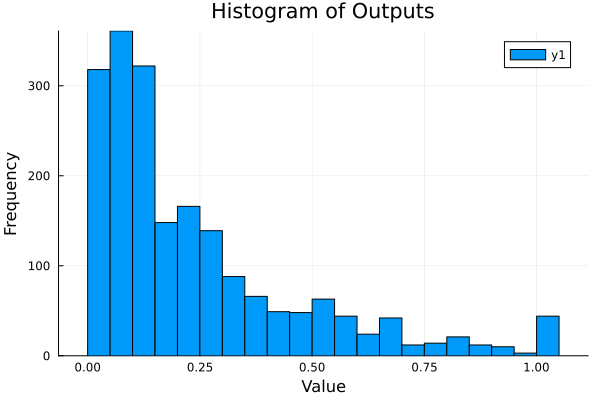

In [248]:
outputs = data[:, end]
histogram(outputs, 
    title="Histogram of Outputs",
    xlabel="Value",
    ylabel="Frequency"
)


In [249]:
edges = [0.25, 0.5, 0.75, 1.0, 6.0]
binned_vector = bin_to_multiclass(outputs, edges)

println("Original Data: ", outputs)
println("Bin Edges: ", edges)
println("Binned Vector (Bin Indices): ", binned_vector)

Original Data: [0.2, 0.67, 0.43, 0.12, 0.03, 0.14, 0.03, 0.55, 0.53, 0.15, 0.24, 0.08, 0.06, 0.09, 0.21, 0.3, 0.49, 0.07, 0.15, 0.03, 0.34, 0.69, 0.21, 0.63, 0.31, 0.12, 0.84, 0.1, 0.49, 0.02, 0.16, 0.19, 0.15, 0.31, 0.08, 0.24, 0.11, 0.22, 0.13, 0.07, 0.11, 0.06, 0.8, 0.22, 0.17, 0.16, 0.2, 0.12, 0.11, 0.12, 0.2, 0.68, 0.23, 0.05, 0.1, 0.28, 0.22, 0.22, 0.55, 0.05, 0.03, 0.07, 0.07, 0.57, 0.37, 0.14, 0.61, 0.03, 0.5, 0.05, 0.04, 0.21, 0.05, 0.02, 0.14, 0.18, 0.12, 0.68, 0.7, 0.75, 0.3, 0.24, 1.0, 0.0, 0.03, 0.06, 0.08, 0.1, 0.27, 0.15, 0.63, 0.05, 0.03, 0.12, 0.4, 0.37, 0.45, 0.04, 0.09, 0.09, 0.39, 0.02, 0.34, 0.28, 0.08, 0.44, 0.24, 0.09, 0.26, 0.4, 0.56, 0.05, 0.06, 0.2, 0.51, 0.04, 0.86, 0.05, 0.06, 0.68, 0.22, 0.05, 0.03, 0.09, 0.17, 0.17, 0.17, 0.14, 0.62, 0.03, 0.23, 0.15, 0.13, 0.27, 0.08, 0.06, 0.09, 0.16, 0.38, 0.02, 0.08, 0.09, 0.3, 0.05, 0.17, 0.53, 1.0, 0.05, 0.63, 1.0, 0.21, 0.86, 0.03, 0.26, 0.87, 0.44, 0.03, 0.73, 0.48, 0.06, 0.07, 0.03, 0.17, 0.11, 0.05, 0.25, 0.05, 0

## Training the models

In [250]:
classifiers = Dict(
    "SVM" => createModel(:SVM, {:kernel=>LIBSVM.Kernel.Linear, :C=>1.0, :gamma=>0.1}),
    "DecisionTree" => createModel(:DecisionTreeClassifier, {:max_depth=>5}),
    "KNN" => createModel(:KNeighborsClassifier, {:n_neighbors=>5}),
    "ANN" => createModel(:ANN, {:n_hidden_layers=>1, :n_neurons_per_layer=>10, :activation=>:relu}),
    "NB"  => GaussianNBClassifier(),
    "LogisticRegression" => LogisticClassifier()
)

LoadError: syntax: { } vector syntax is discontinued around In[250]:1